In [1]:
import torch
import torch._dynamo  # force torch's heavy lazy imports to load before TF/grpc/protobuf
import pandas as pd
import numpy as np
import os
import json
import time
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


# Import from our project
from src.embeddings import (
    pca_embedding, lle_embedding, umap_embedding, 
    wavelet_embedding, fft_embedding, AE_embedding,
    graph_embedding, tda_embedding, 
    nnclr_cnn_embedding, nnclr_lstm_embedding
)
from src.classifiers import (
    optimize_LOGRG, optimize_DT, optimize_RF, optimize_KNN, 
    optimize_XGBOOST, optimize_SVM, optimize_MLP, optimize_NB
)
from src.utils.preprocessing import load_dataset, prepare_dataset
from src.utils.evaluation import (
    evaluate_embeddings, visualize_embeddings, 
    compare_classifiers, generate_classification_report
)
from src.utils.visualization import umap_plt, plot_embedding_comparison



I0000 00:00:1792532900.475052 1432090 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import sys
sys.path.insert(0, "src")
from run_experiments import *

In [3]:
from sklearn.model_selection import train_test_split
# Get the list of countries and their corresponding continents from the provided URL.
url_data = (r'https://raw.githubusercontent.com/oderofrancis/rona/main/Countries-Continents.csv')
data_countries = pd.read_csv(url_data)


""" 
List of countries in the ntl data that are not present in the provided countries-continents CSV file.
{'DR Congo',
 'Mayotte',
 'Myanmar',
 'Myanmar (post-coup)',
 'México',
 'Palestine (Israel)',
 'Puerto Rico',
 'Réunion',
 'Taiwan',
 'United States'}
"""
# Do I make MENA a seperate region? I think I should.

missing_countries = {
    "Continent": [
        "Africa",
        "Africa",
        "Asia",
        "Asia",
        "North America",
        "Asia",
        "North America",
        "Africa",
        "Asia",
        "North America",
    ],
    "Country": [
        "DR Congo",
        "Mayotte",
        "Myanmar",
        "Myanmar (post-coup)",
        "México",
        "Palestine (Israel)",
        "Puerto Rico",
        "Réunion",
        "Taiwan",
        "United States",
    ],
}

data_countries = pd.concat([
    data_countries,
    pd.DataFrame(missing_countries)
], ignore_index=True)
data_countries.rename(columns={"Country": "country"}, inplace=True)


ntl_data = pd.read_csv('final_pre365/ntl_cases.csv')[['case_id', 'time', 'ntl_filled']]
ntl_data['time'] = pd.to_datetime(ntl_data['time'])
ntl_data = ntl_data.sort_values(['case_id', 'time']).reset_index(drop=True)
ntl_data['time_step'] = ntl_data.groupby('case_id').cumcount()

cases = pd.read_csv('final_pre365/cases.csv')
cases['event_date'] = pd.to_datetime(cases['event_date'])
"""
# Split data into train (test) and val
split_cases = pd.read_csv('final/split.csv')
cases = cases.merge(
    split_cases[['case_id', 'split']],
    on='case_id',
    how='left'
)
"""
"""
train_idx, val_idx = train_test_split(
    cases.index,
    test_size=0.2,
    stratify=cases['event_type'],
    random_state=42,
)

cases['split'] = 'train'
cases.loc[val_idx, 'split'] = 'val'

ntl_data = ntl_data.merge(
    cases[['case_id', 'split']],
    on='case_id',
    how='left'
)
"""
# Add the continent/

cases = cases.merge(
    data_countries[['country', 'Continent']],
    on='country',
    how='left'
).set_index('case_id')

event_types = sorted(cases['event_type'].unique())

for date_col in ['event_start', 'event_end', 'window_start', 'window_end']:
    cases[date_col] = pd.to_datetime(cases[date_col] )

feature_list = ['event_type', 'Continent']
feature_dict = dict()
for feature in feature_list:
    feature_value_dict = {feature_value : i for i, feature_value in enumerate(cases[feature].unique())}
    
    cases[feature + '_class'] = cases[feature].map(feature_value_dict)
    feature_dict[feature] = feature_value_dict
    

In [5]:
colors = {'Continent': {
            'Africa':'green', 
            'Asia': 'red',
            'Europe': 'darkviolet',
            'North America': 'blue',
            'South America': 'darkorange',
            'Oceania': 'mediumturquoise'}, 
            'event_type': {'conflict': 'tomato', 'cyclone': 'cadetblue', 'earthquake': 'mediumseagreen', 'flood': 'dodgerblue'}}

In [4]:
from sklearn.preprocessing import StandardScaler
def calculate_window(ntl_data, cases, d_window):
    case_ids = dict()
    frames = []                       # collect pieces, concat once at the end
    cases_window = cases.copy()

    # plain Python float -> no NumPy "generic unit" timedelta warning
    window = pd.Timedelta(days=float(d_window))

    def _rescale(frame):
        frame = frame.copy()          # avoids SettingWithCopyWarning
        frame['time_step'] = frame.groupby('case_id').cumcount()
        frame['ntl_std'] = StandardScaler().fit_transform(
            frame['ntl_filled'].values.reshape(-1, 1)
        ).ravel()
        return frame

    for case_id, df in ntl_data.groupby('case_id'):
        if cases.loc[case_id, 'n_events'] == 1:
            event_date = cases.loc[case_id, 'event_date']
            start_date = event_date - window
            end_date = event_date + window

            cases_window.loc[case_id, 'window_start'] = start_date
            cases_window.loc[case_id, 'window_end'] = end_date

            df = df[(df['time'] >= start_date) & (df['time'] <= end_date)]
            case_ids[case_id] = case_id

            if not df.empty and not df.isna().all().all():
                frames.append(_rescale(df))

        else:
            event_dates = pd.to_datetime(
                list(set(cases.loc[case_id, 'event_dates'].split(';')))
            )
            cases_window.drop(index=case_id, inplace=True)

            for i, event_date in enumerate(event_dates):
                new_case_id = f"{case_id}_event_{i+1}"
                start_date = event_date - window
                end_date = event_date + window

                cases_window.loc[new_case_id] = cases.loc[case_id]
                cases_window.loc[new_case_id, 'event_date'] = event_date
                cases_window.loc[new_case_id, 'window_start'] = start_date
                cases_window.loc[new_case_id, 'window_end'] = end_date

                case_ids[new_case_id] = case_id

                df_event = df[(df['time'] >= start_date) & (df['time'] <= end_date)]

                if not df_event.empty and not df_event.isna().all().all():
                    df_event = df_event.copy()
                    df_event['case_id'] = new_case_id   # set before cumcount
                    frames.append(_rescale(df_event))

    new_ntl = (pd.concat(frames, ignore_index=True)
               if frames else pd.DataFrame(columns=ntl_data.columns))
    
    cases_window['original_id'] = cases_window.index.map(case_ids)

    return case_ids, new_ntl, cases_window

In [ ]:
embedding_methods = ['pca', 'lle','wavelet', 'fft', 'autoencoder', 'graph', 'tda', 'umap','nnclr_cnn','nnclr_lstm']

#embedding_methods = ['wavelet', 'fft', 'autoencoder', 'graph', 'tda']
classifiers = ['logreg', 'dt', 'rf', 'knn','xgboost', 'svm', 'mlp','nb']

all_results = {}   # {"<feature>_<window>": results_dict}
all_rows = []      # flat rows for one combined CSV
for feature in feature_list:
    train_idx, val_idx = train_test_split(
        cases.index,
        test_size=0.2,
        stratify=cases[feature],
        random_state=42,
    )
    cases = cases.drop(columns=f'split_{feature}', errors='ignore')
    ntl_data = ntl_data.drop(columns=f'split_{feature}', errors='ignore')
    cases[f'split_{feature}'] = 'train'
    cases.loc[val_idx, f'split_{feature}'] = 'val'

    ntl_data = ntl_data.merge(
    cases[[f'split_{feature}']].reset_index(inplace=False),
    on='case_id',
    how='left')
            
    
    for d_window in [7, 14, 30]:
        case_ids,  ntl_window, cases_window = calculate_window(ntl_data, cases, d_window)
        results = {
                'dataset': feature + '_' + str(d_window),
                'embedding_results': {},
                'classifier_results': {},
                'combined_results': {}
            }
        X_train_norm = ntl_window[ntl_window[f'split_{feature}'] == 'train'].pivot(index='case_id', columns='time_step', values='ntl_std').dropna()
        X_val_norm = ntl_window[ntl_window[f'split_{feature}'] == 'val'].pivot(index='case_id', columns='time_step', values='ntl_std').dropna()
        X_test_norm = X_val_norm
        #X_full = ntl_window.pivot(index='case_id', columns='time_step', values='ntl_std').dropna()
        
        

        dataset_path = f'results/{feature}/data_{str(d_window)}/data_{str(d_window)}'
        os.makedirs(f'results/{feature}/data_{str(d_window)}',exist_ok=True)

        output_dir = f'plots/{feature}/data_{str(d_window)}'
        os.makedirs(output_dir ,exist_ok=True)

        y_train = cases_window.loc[X_train_norm.index, feature + '_class'].values
        y_val = cases_window.loc[X_val_norm.index, feature + '_class'].values
        y_test =y_val
        
        y_train_labels = cases_window.loc[X_train_norm.index, feature].values
        y_val_labels = cases_window.loc[X_val_norm.index, feature ].values
        y_test_labels =y_val_labels

        for embed_method in embedding_methods:
            print(f"\nEvaluating embedding method: {embed_method}")
            # Run embedding
            try:
                train_emb, val_emb, test_emb, embed_time = run_embedding_experiment(
            X_train_norm.values, X_val_norm.values, X_test_norm, y_train, y_val, y_test, embed_method
                )

                # Store embedding results
                results['embedding_results'][embed_method] = {
                'time': embed_time,
                'shape': train_emb.shape if hasattr(train_emb, 'shape') else None
                }

                # Visualize embeddings
                try:
                    if embed_method in ['nnclr_cnn', 'nnclr_lstm']:
                        # For NNCLR methods, use umap_plt from visualization module
                        umap_plt(
                        train_emb, val_emb, test_emb, 
                        y_train_labels, y_val_labels, y_test_labels,
                        f"{embed_method.upper()} Embedding (window = {d_window})", colors= colors[feature], filename=os.path.join(output_dir, f'{embed_method}_umap_visualization.png')
                            )
                    else:
                        # For other methods, use visualize_embeddings from evaluation module
                        fig = visualize_embeddings(
                        train_emb,labels= y_train_labels, method='umap', colors= colors[feature],
                        title=f'{embed_method.upper()} Embedding Visualization (window = {d_window})'
                            )
                        fig.savefig(os.path.join(output_dir, f'{embed_method}_umap_visualization.png'))
                        plt.close(fig)
                except Exception as viz_error:
                    print(f"  - Warning: Visualization failed: {viz_error}")

                # Run classifier experiments
                for clf_name in classifiers:
                    print(f"  - Testing classifier: {clf_name}")

                    experiment_name = f"{dataset_path}_{embed_method}_{clf_name}"

                    try:
                        best_params, test_score, clf_time = run_classifier_experiment(
                train_emb, val_emb, test_emb, y_train, y_val, y_test, 
                clf_name, experiment_name
                    )

                        # Store results
                        if embed_method not in results['combined_results']:
                            results['combined_results'][embed_method] = {}

                        results['combined_results'][embed_method][clf_name] = {
                    'accuracy': test_score,
                    'params': best_params,
                    'time': clf_time
                        }

                        print(f"    Accuracy: {test_score:.4f}, Time: {clf_time:.2f}s")

                    except Exception as e:
                        print(f"    Error with classifier {clf_name}: {e}")
                        results['combined_results'][embed_method][clf_name] = {
                    'error': str(e)
                    }
                    

            except Exception as e:
                print(f"Error with embedding method {embed_method}: {e}")
                results['embedding_results'][embed_method] = {
                'error': str(e)
                    }
                
                
        # Save results
        all_results[feature + '_' +str( d_window)] = results
        for emb, clfs in results['combined_results'].items():
            for clf, m in clfs.items():
                all_rows.append({
                        'feature': feature,
                        'window': d_window,
                        'embedding': emb,
                        'classifier': clf,
                        'accuracy': m.get('accuracy'),
                        'time': m.get('time'),
                        'params': m.get('params'),
                        'error': m.get('error'),
                    })
        


timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

pd.DataFrame(all_rows).to_csv(f'results/all_results_{timestamp}.csv', index=False)

with open(f'results/all_results_{timestamp}.json', 'w') as f:
    json.dump(all_results, f, indent=2, default=str)   # default=str handles numpy types / params
        

In [14]:
all_results = pd.DataFrame(all_rows)

In [18]:
all_results[all_results['accuracy'] == all_results['accuracy'].max()]

,feature,window,embedding,classifier,accuracy,time,params,error
131,event_type,30,pca,knn,0.722222,0.347256,"{'n_neighbors': 11, 'weights': 'distance', 'al...",None
163,event_type,30,autoencoder,knn,0.722222,0.346349,"{'n_neighbors': 14, 'weights': 'uniform', 'alg...",None
171,event_type,30,umap,knn,0.722222,0.322680,"{'n_neighbors': 18, 'weights': 'uniform', 'alg...",None


In [19]:
all_results[all_results['accuracy'] == all_results['accuracy'].min()]

,feature,window,embedding,classifier,accuracy,time,params,error
319,Continent,14,nnclr_lstm,nb,0.12987,0.418403,{'var_smoothing': 1.9237096218791365e-10},None


In [26]:
all_results.sort_values('accuracy', ascending=False)

,feature,window,embedding,classifier,accuracy,time,params,error
131,event_type,30,pca,knn,0.722222,0.347256,"{'n_neighbors': 11, 'weights': 'distance', 'al...",None
171,event_type,30,umap,knn,0.722222,0.322680,"{'n_neighbors': 18, 'weights': 'uniform', 'alg...",None
163,event_type,30,autoencoder,knn,0.722222,0.346349,"{'n_neighbors': 14, 'weights': 'uniform', 'alg...",None
67,event_type,14,pca,knn,0.708333,0.342059,"{'n_neighbors': 16, 'weights': 'distance', 'al...",None
85,event_type,14,wavelet,svm,0.708333,0.566713,"{'C': 1, 'kernel': 'rbf', 'degree': 4, 'gamma'...",None
...,...,...,...,...,...,...,...,...
383,Continent,30,nnclr_lstm,nb,0.220779,0.389434,{'var_smoothing': 0.00011439242803846489},None
375,Continent,30,nnclr_cnn,nb,0.207792,0.411984,{'var_smoothing': 1.0191138755910888e-07},None
335,Continent,30,lle,nb,0.181818,0.239276,{'var_smoothing': 7.199524882510653e-06},None
255,Continent,7,nnclr_lstm,nb,0.155844,0.407474,{'var_smoothing': 1.2608935145233537e-09},None


In [5]:
# par zone economique
socioeconomic_codes = {
    # Low income
    "Mozambique": 'low income',
    "Madagascar": 'low income',
    "Malawi": 'low income',
    "Niger": 'low income',
    "Somalia": 'low income',
    "Afghanistan": 'low income',
    "DR Congo": 'low income',
    "Sudan": 'low income',
    "Ethiopia": 'low income',
    # Special / unclassified
    "Venezuela": 'low income',
    "Cuba": 'low income',

    # Lower-middle income
    "Myanmar": 'lower-middle income',
    "Nicaragua": 'lower-middle income',
    "Philippines": 'lower-middle income',
    "India": 'lower-middle income',
    "Vanuatu": 'lower-middle income',
    "Vietnam": 'lower-middle income',
    "Morocco": 'lower-middle income',
    "Bangladesh": 'lower-middle income',
    "Pakistan": 'lower-middle income',
    "Nepal": 'lower-middle income',
    "Cabo Verde": 'lower-middle income',
    "Palestine (Israel)": 'lower-middle income',
    "Myanmar (post-coup)": 'lower-middle income',
    "Lebanon": 'lower-middle income',

    # Upper-middle income
    "Iraq": 'upper-middle income',
    "Turkey": 'upper-middle income',
    "Indonesia": 'upper-middle income',
    "Fiji": 'upper-middle income',
    "México": 'upper-middle income',
    "Jamaica": 'upper-middle income',
    "China": 'upper-middle income',
    "Argentina": 'upper-middle income',
    "Brazil": 'upper-middle income',
    "Iran": 'upper-middle income',
    "Ukraine": 'upper-middle income',

    # High income
    "Chile": 'high income',
    "Russia": 'high income',
    "Taiwan": 'high income',
    "United States": 'high income',
    "Puerto Rico": 'high income',
    "Bahamas": 'high income',
    "Mayotte": 'high income',
    "Oman": 'high income',
    "Réunion": 'high income',
    "Japan": 'high income',
    "Italy": 'high income',
    "Spain": 'high income',
    "Canada": 'high income',
    "Germany": 'high income',
    "Netherlands": 'high income',

    
}



cases["socioeconomic_code"] = cases["country"].map(
    socioeconomic_codes
)

for feature in ["socioeconomic_code"]:
    feature_value_dict = {feature_value : i for i, feature_value in enumerate(cases[feature].unique())}
    
    cases[feature + '_class'] = cases[feature].map(feature_value_dict)
    feature_dict[feature] = feature_value_dict

In [6]:
colors = {'Continent': {
            'Africa':'green', 
            'Asia': 'red',
            'Europe': 'darkviolet',
            'North America': 'blue',
            'South America': 'darkorange',
            'Oceania': 'mediumturquoise'}, 
            'event_type': {'conflict': 'tomato', 'cyclone': 'cadetblue', 'earthquake': 'mediumseagreen', 'flood': 'dodgerblue'},
            
            'socioeconomic_code' : {  'low income': 'red', 'lower-middle income': 'gold', 'upper-middle income': 'deeppink', 'high income': 'blue'}}


Evaluating embedding method: pca


/home/zeineb/.conda/envs/timeseries_py312/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
[I 2026-10-20 23:49:05,376] A new study created in memory with name: no-name-ac4a4527-ea70-4c41-9b89-76273de57c39
[I 2026-10-20 23:49:05,465] Trial 0 finished with value: 0.352112676056338 and parameters: {'C': 0.05232515595890154, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.7564683242479764}. Best is trial 0 with value: 0.352112676056338.
[I 2026-10-20 23:49:05,539] Trial 1 finished with value: 0.352112676056338 and parameters: {'C': 0.03849776143047141, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.2741264299758197}. Best is trial 0 with value: 0.352112676056338.


  - Testing classifier: logreg


[I 2026-10-20 23:49:05,642] Trial 2 finished with value: 0.29577464788732394 and parameters: {'C': 1.5125355662583286, 'fit_intercept': False, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.6486324239700201}. Best is trial 0 with value: 0.352112676056338.
[I 2026-10-20 23:49:05,857] Trial 3 finished with value: 0.29577464788732394 and parameters: {'C': 27.5559231674454, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.3891341271049692}. Best is trial 0 with value: 0.352112676056338.
[I 2026-10-20 23:49:05,937] Trial 4 finished with value: 0.29577464788732394 and parameters: {'C': 2.0108915479690116e-06, 'fit_intercept': False, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.9937136934312482}. Best is trial 0 with value: 0.352112676056338.
[I 2026-10-20 23:49:06,010] Trial 5 finished with value: 0.3380281690140845 and parameters: {'C': 0.04228845164786566, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.72

0.007767915725708008  seconds
Classification report saved as results/socioeconomic_code/data_7/data_7_pca_logreg_classification_report.txt
    Accuracy: 0.3662, Time: 8.04s
  - Testing classifier: dt


...

Epoch 16/20 - loss: 2.6735


Epoch 17/20 - loss: 2.6009


Epoch 18/20 - loss: 2.5689


Epoch 19/20 - loss: 2.5805


Epoch 20/20 - loss: 2.4775
Generating embeddings...


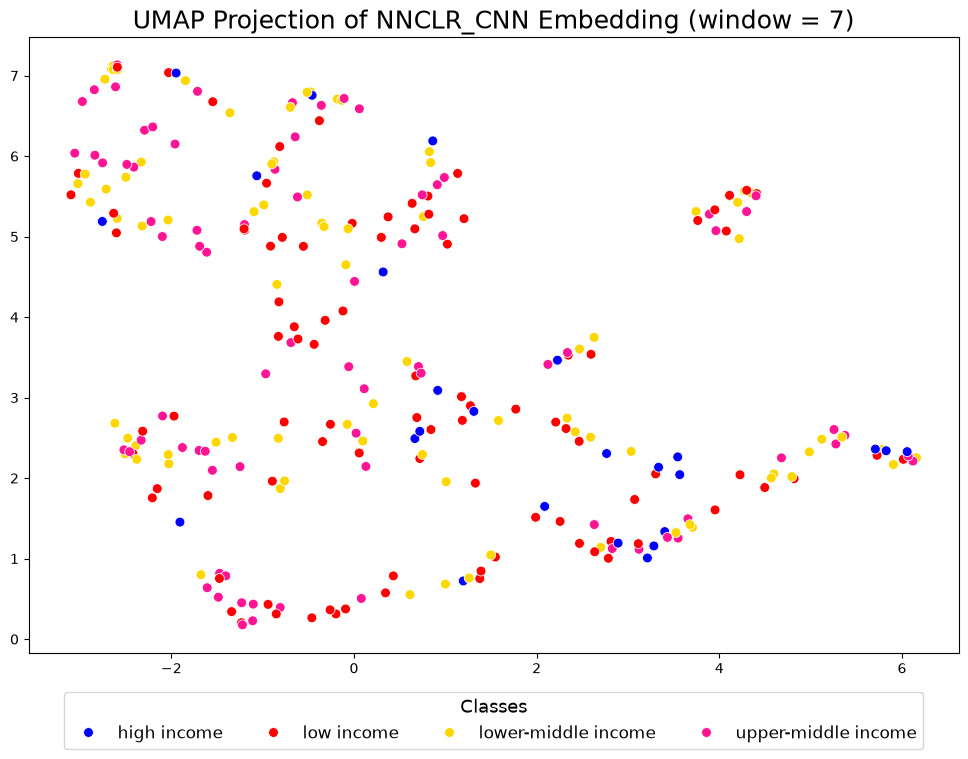

[I 2026-10-21 00:14:11,313] A new study created in memory with name: no-name-ef4f7ddb-5513-4cb5-9af7-30a1aa6f6ffc


  - Testing classifier: logreg


[I 2026-10-21 00:14:12,514] Trial 0 finished with value: 0.30985915492957744 and parameters: {'C': 84.41961940426899, 'fit_intercept': False, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.13670793296727324}. Best is trial 0 with value: 0.30985915492957744.
[I 2026-10-21 00:14:12,586] Trial 1 finished with value: 0.36619718309859156 and parameters: {'C': 0.63395916441626, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.3131272335642472}. Best is trial 1 with value: 0.36619718309859156.
[I 2026-10-21 00:14:12,606] Trial 2 finished with value: 0.323943661971831 and parameters: {'C': 0.0003250572958082906, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.8972990103502574}. Best is trial 1 with value: 0.36619718309859156.
[I 2026-10-21 00:14:12,628] Trial 3 finished with value: 0.323943661971831 and parameters: {'C': 3.6139203559445566e-09, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 

0.035552978515625  seconds
Classification report saved as results/socioeconomic_code/data_7/data_7_nnclr_cnn_logreg_classification_report.txt
    Accuracy: 0.3803, Time: 25.83s
  - Testing classifier: dt


[I 2026-10-21 00:14:37,341] Trial 12 finished with value: 0.39436619718309857 and parameters: {'max_depth': 13, 'criterion': 'gini'}. Best is trial 6 with value: 0.4225352112676056.
[I 2026-10-21 00:14:37,355] Trial 13 finished with value: 0.38028169014084506 and parameters: {'max_depth': 8, 'criterion': 'gini'}. Best is trial 6 with value: 0.4225352112676056.
[I 2026-10-21 00:14:37,366] Trial 14 finished with value: 0.30985915492957744 and parameters: {'max_depth': 3, 'criterion': 'log_loss'}. Best is trial 6 with value: 0.4225352112676056.
[I 2026-10-21 00:14:37,381] Trial 15 finished with value: 0.36619718309859156 and parameters: {'max_depth': 5, 'criterion': 'entropy'}. Best is trial 6 with value: 0.4225352112676056.
[I 2026-10-21 00:14:37,396] Trial 16 finished with value: 0.36619718309859156 and parameters: {'max_depth': 15, 'criterion': 'gini'}. Best is trial 6 with value: 0.4225352112676056.
[I 2026-10-21 00:14:37,411] Trial 17 finished with value: 0.4225352112676056 and param

...

Epoch 16/20 - loss: 3.3007


Epoch 17/20 - loss: 3.1750


Epoch 18/20 - loss: 3.2646


Epoch 19/20 - loss: 3.1464


Epoch 20/20 - loss: 3.0530
Generating embeddings...


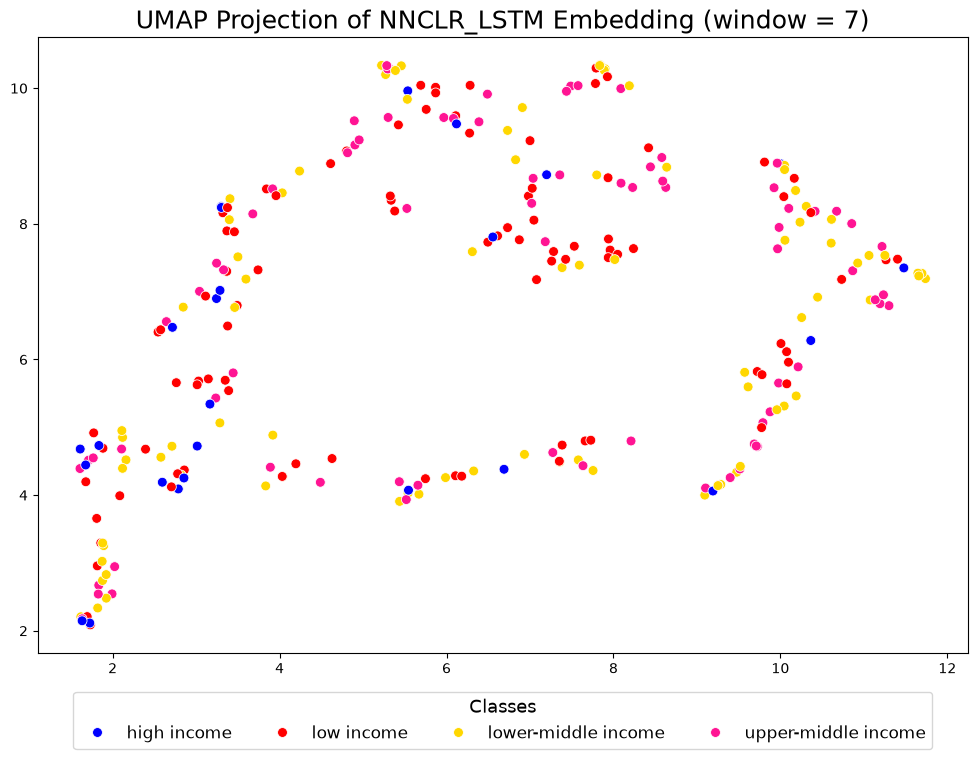

[I 2026-10-21 01:02:34,838] A new study created in memory with name: no-name-a863da4f-2876-4e9a-be57-d155de8a061f
[I 2026-10-21 01:02:34,877] Trial 0 finished with value: 0.38028169014084506 and parameters: {'C': 0.48172014532268964, 'fit_intercept': False, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.31747912516383714}. Best is trial 0 with value: 0.38028169014084506.
[I 2026-10-21 01:02:35,026] Trial 1 finished with value: 0.36619718309859156 and parameters: {'C': 6.293771480256595, 'fit_intercept': False, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.00043866808328563156}. Best is trial 0 with value: 0.38028169014084506.


  - Testing classifier: logreg


[I 2026-10-21 01:02:35,048] Trial 2 finished with value: 0.323943661971831 and parameters: {'C': 8.672790929511164e-10, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.7687221337622591}. Best is trial 0 with value: 0.38028169014084506.
[I 2026-10-21 01:02:36,807] Trial 3 finished with value: 0.323943661971831 and parameters: {'C': 212.86707134433087, 'fit_intercept': False, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.27857804703378286}. Best is trial 0 with value: 0.38028169014084506.
[I 2026-10-21 01:02:36,829] Trial 4 finished with value: 0.323943661971831 and parameters: {'C': 1.1227840598203736e-06, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.37174387940570053}. Best is trial 0 with value: 0.38028169014084506.
[I 2026-10-21 01:02:36,851] Trial 5 finished with value: 0.323943661971831 and parameters: {'C': 2.2904693079207825e-06, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_rati

0.11287951469421387  seconds
Classification report saved as results/socioeconomic_code/data_7/data_7_nnclr_lstm_logreg_classification_report.txt
    Accuracy: 0.4225, Time: 53.96s
  - Testing classifier: dt


[I 2026-10-21 01:03:28,994] Trial 6 finished with value: 0.2112676056338028 and parameters: {'max_depth': 22, 'criterion': 'gini'}. Best is trial 4 with value: 0.352112676056338.
[I 2026-10-21 01:03:29,028] Trial 7 finished with value: 0.29577464788732394 and parameters: {'max_depth': 19, 'criterion': 'log_loss'}. Best is trial 4 with value: 0.352112676056338.
[I 2026-10-21 01:03:29,056] Trial 8 finished with value: 0.2676056338028169 and parameters: {'max_depth': 6, 'criterion': 'log_loss'}. Best is trial 4 with value: 0.352112676056338.
[I 2026-10-21 01:03:29,081] Trial 9 finished with value: 0.19718309859154928 and parameters: {'max_depth': 16, 'criterion': 'gini'}. Best is trial 4 with value: 0.352112676056338.
[I 2026-10-21 01:03:29,101] Trial 10 finished with value: 0.29577464788732394 and parameters: {'max_depth': 3, 'criterion': 'entropy'}. Best is trial 4 with value: 0.352112676056338.
[I 2026-10-21 01:03:29,116] Trial 11 finished with value: 0.28169014084507044 and parameters

...

Epoch 16/20 - loss: 2.7094


Epoch 17/20 - loss: 2.4281


Epoch 18/20 - loss: 2.3843


Epoch 19/20 - loss: 2.5031


Epoch 20/20 - loss: 2.4441
Generating embeddings...


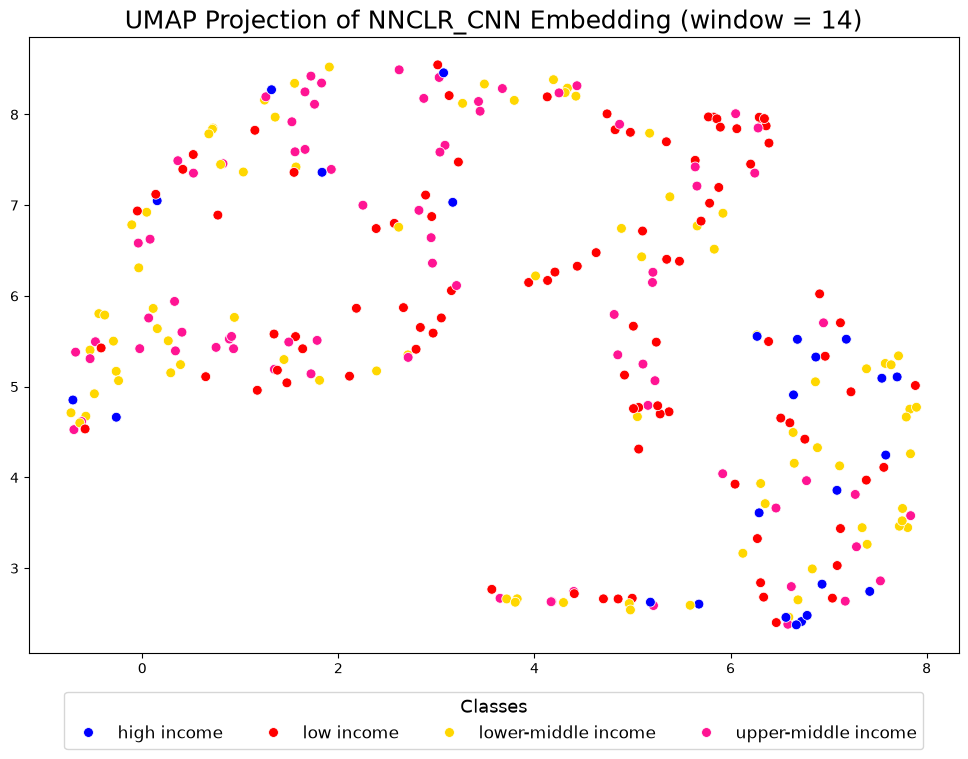

[I 2026-10-21 01:27:26,509] A new study created in memory with name: no-name-3f73be05-77f4-4155-a07a-64496a423264


  - Testing classifier: logreg


[I 2026-10-21 01:27:26,830] Trial 0 finished with value: 0.39436619718309857 and parameters: {'C': 9.30270623177918, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.4620672588499781}. Best is trial 0 with value: 0.39436619718309857.
[I 2026-10-21 01:27:26,851] Trial 1 finished with value: 0.323943661971831 and parameters: {'C': 0.0007393444410677935, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.7354766097096037}. Best is trial 0 with value: 0.39436619718309857.
[I 2026-10-21 01:27:28,276] Trial 2 finished with value: 0.43661971830985913 and parameters: {'C': 177.27235731853273, 'fit_intercept': False, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.1404475127728565}. Best is trial 2 with value: 0.43661971830985913.
[I 2026-10-21 01:27:28,318] Trial 3 finished with value: 0.4225352112676056 and parameters: {'C': 0.24758272180861954, 'fit_intercept': False, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0

0.1025383472442627  seconds
Classification report saved as results/socioeconomic_code/data_14/data_14_nnclr_cnn_logreg_classification_report.txt
    Accuracy: 0.4225, Time: 52.83s
  - Testing classifier: dt


[I 2026-10-21 01:28:19,556] Trial 11 finished with value: 0.43661971830985913 and parameters: {'max_depth': 10, 'criterion': 'log_loss'}. Best is trial 1 with value: 0.43661971830985913.
[I 2026-10-21 01:28:19,572] Trial 12 finished with value: 0.36619718309859156 and parameters: {'max_depth': 30, 'criterion': 'gini'}. Best is trial 1 with value: 0.43661971830985913.
[I 2026-10-21 01:28:19,594] Trial 13 finished with value: 0.39436619718309857 and parameters: {'max_depth': 23, 'criterion': 'entropy'}. Best is trial 1 with value: 0.43661971830985913.
[I 2026-10-21 01:28:19,616] Trial 14 finished with value: 0.352112676056338 and parameters: {'max_depth': 30, 'criterion': 'log_loss'}. Best is trial 1 with value: 0.43661971830985913.
[I 2026-10-21 01:28:19,635] Trial 15 finished with value: 0.4225352112676056 and parameters: {'max_depth': 6, 'criterion': 'entropy'}. Best is trial 1 with value: 0.43661971830985913.
[I 2026-10-21 01:28:19,651] Trial 16 finished with value: 0.352112676056338

...

Epoch 16/20 - loss: 3.1308


Epoch 17/20 - loss: 3.0670


Epoch 18/20 - loss: 3.0804


Epoch 19/20 - loss: 2.9388


Epoch 20/20 - loss: 2.9359
Generating embeddings...


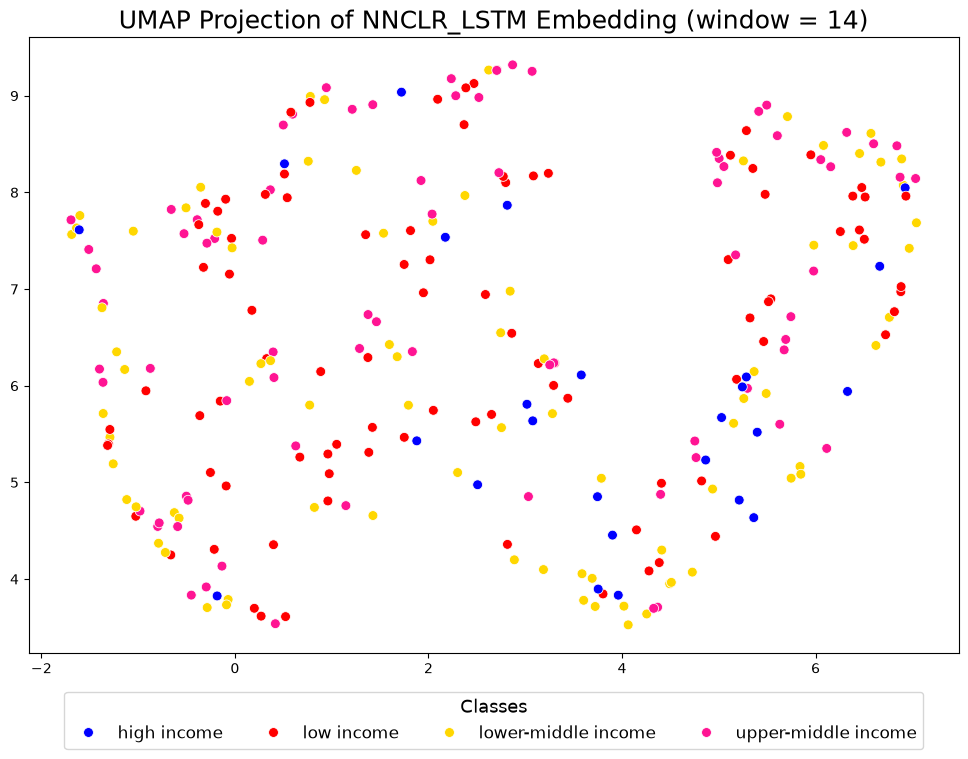

[I 2026-10-21 01:31:37,881] A new study created in memory with name: no-name-247b2a37-f230-4e20-85db-358c49b54050


  - Testing classifier: logreg


[I 2026-10-21 01:31:41,317] Trial 0 finished with value: 0.352112676056338 and parameters: {'C': 160.1953875006592, 'fit_intercept': True, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.7979009989491945}. Best is trial 0 with value: 0.352112676056338.
[I 2026-10-21 01:31:41,337] Trial 1 finished with value: 0.29577464788732394 and parameters: {'C': 1.246220377385114e-07, 'fit_intercept': False, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.9717695858907268}. Best is trial 0 with value: 0.352112676056338.
[I 2026-10-21 01:31:41,354] Trial 2 finished with value: 0.29577464788732394 and parameters: {'C': 1.9165688711143916e-06, 'fit_intercept': False, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio': 0.3451045709292856}. Best is trial 0 with value: 0.352112676056338.
[I 2026-10-21 01:31:41,375] Trial 3 finished with value: 0.29577464788732394 and parameters: {'C': 0.00046905209413403685, 'fit_intercept': False, 'solver': 'saga', 'penalty': 'elasticnet', 'l1_ratio

In [ ]:
embedding_methods = ['pca', 'lle','wavelet', 'fft', 'autoencoder', 'graph', 'tda', 'umap','nnclr_cnn','nnclr_lstm']

#embedding_methods = ['wavelet', 'fft', 'autoencoder', 'graph', 'tda']
classifiers = ['logreg', 'dt', 'rf', 'knn','xgboost', 'svm', 'mlp','nb']

all_results = {}   # {"<feature>_<window>": results_dict}
all_rows = []      # flat rows for one combined CSV
for feature in ['socioeconomic_code']:
    train_idx, val_idx = train_test_split(
        cases.index,
        test_size=0.2,
        stratify=cases[feature],
        random_state=42,
    )
    cases = cases.drop(columns=f'split_{feature}', errors='ignore')
    ntl_data = ntl_data.drop(columns=f'split_{feature}', errors='ignore')
    cases[f'split_{feature}'] = 'train'
    cases.loc[val_idx, f'split_{feature}'] = 'val'

    ntl_data = ntl_data.merge(
    cases[[f'split_{feature}']].reset_index(inplace=False),
    on='case_id',
    how='left')
            
    
    for d_window in [7, 14, 30]:
        case_ids,  ntl_window, cases_window = calculate_window(ntl_data, cases, d_window)
        results = {
                'dataset': feature + '_' + str(d_window),
                'embedding_results': {},
                'classifier_results': {},
                'combined_results': {}
            }
        X_train_norm = ntl_window[ntl_window[f'split_{feature}'] == 'train'].pivot(index='case_id', columns='time_step', values='ntl_std').dropna()
        X_val_norm = ntl_window[ntl_window[f'split_{feature}'] == 'val'].pivot(index='case_id', columns='time_step', values='ntl_std').dropna()
        X_test_norm = X_val_norm
        #X_full = ntl_window.pivot(index='case_id', columns='time_step', values='ntl_std').dropna()
        
        

        dataset_path = f'results/{feature}/data_{str(d_window)}/data_{str(d_window)}'
        os.makedirs(f'results/{feature}/data_{str(d_window)}',exist_ok=True)

        output_dir = f'plots/{feature}/data_{str(d_window)}'
        os.makedirs(output_dir ,exist_ok=True)

        y_train = cases_window.loc[X_train_norm.index, feature + '_class'].values
        y_val = cases_window.loc[X_val_norm.index, feature + '_class'].values
        y_test =y_val
        
        y_train_labels = cases_window.loc[X_train_norm.index, feature].values
        y_val_labels = cases_window.loc[X_val_norm.index, feature ].values
        y_test_labels =y_val_labels

        for embed_method in embedding_methods:
            print(f"\nEvaluating embedding method: {embed_method}")
            # Run embedding
            try:
                train_emb, val_emb, test_emb, embed_time = run_embedding_experiment(
            X_train_norm.values, X_val_norm.values, X_test_norm, y_train, y_val, y_test, embed_method
                )

                # Store embedding results
                results['embedding_results'][embed_method] = {
                'time': embed_time,
                'shape': train_emb.shape if hasattr(train_emb, 'shape') else None
                }

                # Visualize embeddings
                try:
                    if embed_method in ['nnclr_cnn', 'nnclr_lstm']:
                        # For NNCLR methods, use umap_plt from visualization module
                        umap_plt(
                        train_emb, val_emb, test_emb, 
                        y_train_labels, y_val_labels, y_test_labels,
                        f"{embed_method.upper()} Embedding (window = {d_window})", colors= colors[feature], filename=os.path.join(output_dir, f'{embed_method}_umap_visualization.png')
                            )
                    else:
                        # For other methods, use visualize_embeddings from evaluation module
                        fig = visualize_embeddings(
                        train_emb,labels= y_train_labels, method='umap', colors= colors[feature],
                        title=f'{embed_method.upper()} Embedding Visualization (window = {d_window})'
                            )
                        fig.savefig(os.path.join(output_dir, f'{embed_method}_umap_visualization.png'))
                        plt.close(fig)
                except Exception as viz_error:
                    print(f"  - Warning: Visualization failed: {viz_error}")

                # Run classifier experiments
                for clf_name in classifiers:
                    print(f"  - Testing classifier: {clf_name}")

                    experiment_name = f"{dataset_path}_{embed_method}_{clf_name}"

                    try:
                        best_params, test_score, clf_time = run_classifier_experiment(
                train_emb, val_emb, test_emb, y_train, y_val, y_test, 
                clf_name, experiment_name
                    )

                        # Store results
                        if embed_method not in results['combined_results']:
                            results['combined_results'][embed_method] = {}

                        results['combined_results'][embed_method][clf_name] = {
                    'accuracy': test_score,
                    'params': best_params,
                    'time': clf_time
                        }

                        print(f"    Accuracy: {test_score:.4f}, Time: {clf_time:.2f}s")

                    except Exception as e:
                        print(f"    Error with classifier {clf_name}: {e}")
                        results['combined_results'][embed_method][clf_name] = {
                    'error': str(e)
                    }
                    

            except Exception as e:
                print(f"Error with embedding method {embed_method}: {e}")
                results['embedding_results'][embed_method] = {
                'error': str(e)
                    }
                
                
        # Save results
        all_results[feature + '_' +str( d_window)] = results
        for emb, clfs in results['combined_results'].items():
            for clf, m in clfs.items():
                all_rows.append({
                        'feature': feature,
                        'window': d_window,
                        'embedding': emb,
                        'classifier': clf,
                        'accuracy': m.get('accuracy'),
                        'time': m.get('time'),
                        'params': m.get('params'),
                        'error': m.get('error'),
                    })
        


timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

pd.DataFrame(all_rows).to_csv(f'results/all_results_{timestamp}.csv', index=False)

with open(f'results/all_results_{timestamp}.json', 'w') as f:
    json.dump(all_results, f, indent=2, default=str)   # default=str handles numpy types / params
        